In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel(r"C:\Users\Lenovo\OneDrive\Desktop\intershala\Machine_learning\course_Assignments\final_Project\customer_churn.xlsx")



In [10]:
print(df.head())
print(df.tail())
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

  customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0   CUST1000    Male              0     Yes         No      42          Yes   
1   CUST1001    Male              1     Yes        Yes      16          Yes   
2   CUST1002  Female              1      No         No       9           No   
3   CUST1003  Female              0      No         No      10          Yes   
4   CUST1004  Female              1      No         No       9          Yes   

  MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0           Yes             DSL            Yes  ...               No   
1           Yes     Fiber optic             No  ...              Yes   
2            No     Fiber optic            Yes  ...              Yes   
3           Yes              No             No  ...               No   
4            No     Fiber optic            Yes  ...               No   

  TechSupport StreamingTV StreamingMovies  Contract PaperlessBilling  \
0         Yes       

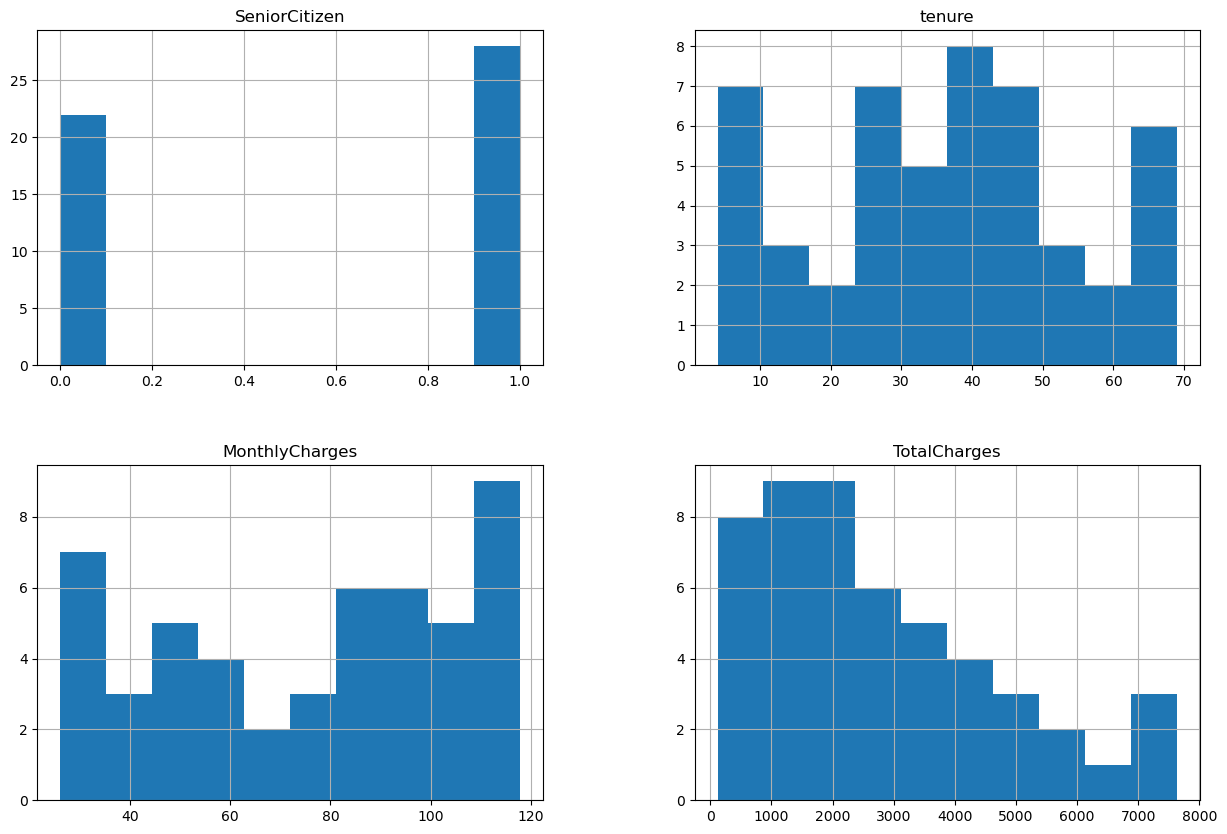

In [11]:
#EDA
df.hist(figsize=(15,10))
plt.show()

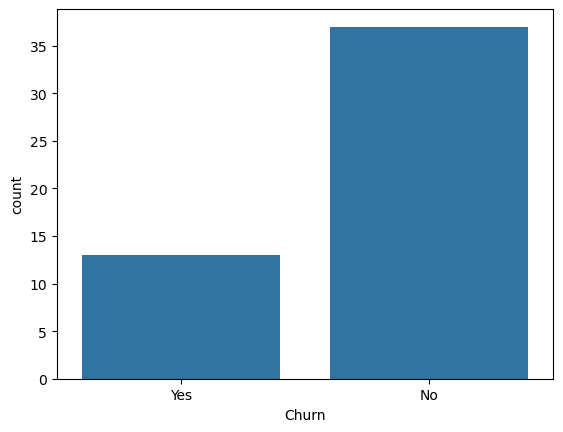

In [12]:
sns.countplot(x="Churn", data=df)
plt.show()


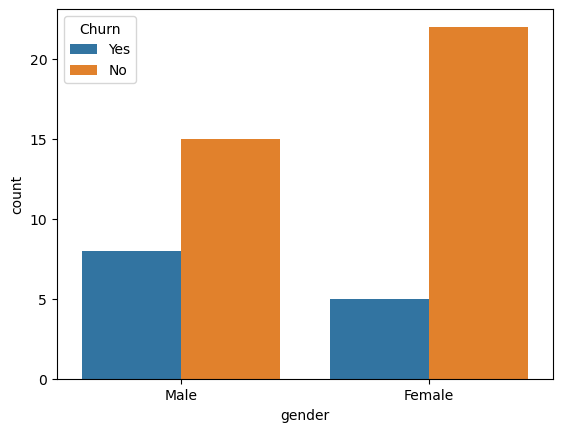

In [13]:
#Gender vs Churn
sns.countplot(x="gender",hue="Churn" ,data=df)
plt.show()

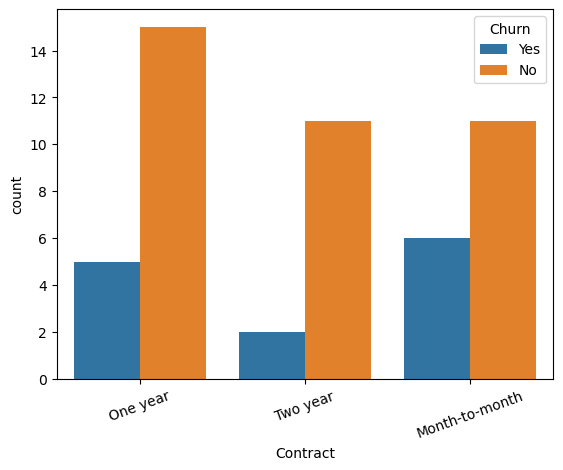

In [14]:
#contract vs churn
sns.countplot(x="Contract",hue="Churn",data=df)
plt.xticks(rotation=20)
plt.show()

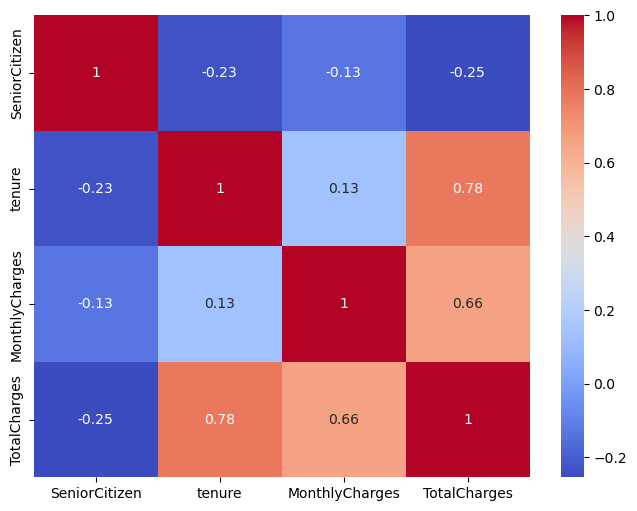

In [15]:
numeric_df=df.select_dtypes(include=['int64','float64'])

plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(),annot=True,cmap="coolwarm")
plt.show()

In [20]:
#Data Preprocessing


In [19]:
print(df.isnull().sum())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [21]:
df.fillna(method='ffill',inplace=True)

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_13568\4116506308.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill',inplace=True)


In [23]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
for column in df.columns:
    if df[column].dtype=='object':
        df[column]=le.fit_transform(df[column])

print(df.head)

<bound method NDFrame.head of     gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0        1              0        1           0      42             1   
1        1              1        1           1      16             1   
2        0              1        0           0       9             0   
3        0              0        0           0      10             1   
4        0              1        0           0       9             1   
5        0              0        0           0      64             0   
6        0              1        0           1      24             1   
7        1              0        1           1      27             1   
8        0              1        1           1      15             1   
9        0              1        1           0      39             1   
10       1              1        0           0       4             0   
11       1              1        1           0      45             1   
12       1              1        0

In [25]:
X=df.drop("Churn",axis=1)

y=df["Churn"]

In [26]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
  X,y,test_size=0.20,random_state=42   
)

In [27]:
#Logisic Regression Model

from sklearn.linear_model import LogisticRegression
model=LogisticRegression(max_iter=1000)

model.fit(X_train,y_train)

C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [28]:
y_pred=model.predict(X_test)

print(y_pred)

[0 0 0 0 0 0 0 0 0 0]


In [29]:
from sklearn.metrics import accuracy_score

accuracy=accuracy_score(y_test,y_pred)

print("Accuracy=",accuracy)

Accuracy= 0.8


[[8 0]
 [2 0]]


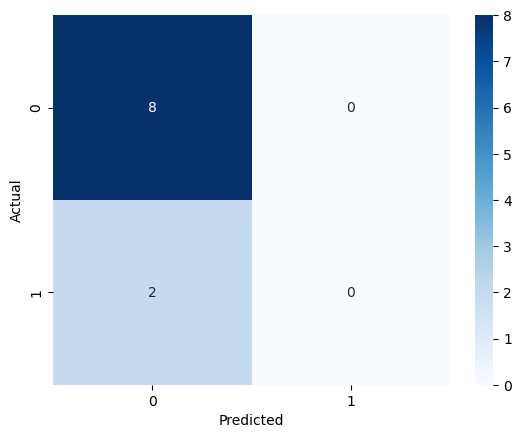

In [30]:
#confusion matrix

from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)

print(cm)

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()





In [31]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      1.00      0.89         8
           1       0.00      0.00      0.00         2

    accuracy                           0.80        10
   macro avg       0.40      0.50      0.44        10
weighted avg       0.64      0.80      0.71        10



C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Lenovo\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [ ]:
new_customer=x.iloc[[0]]
prediction=mode